In [1]:
# 1. IMPORTS AND SETTINGS

# Can compare versions if ever needed

import sys
import cloudpickle #CloudPickle daw dapat sabi sa dojo specs
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction import DictVectorizer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

LABELS = ['FIL', 'ENG', 'CS', 'OTH']

# Fixed seed para same results every run
# Important din para same output sa atin lahat
RANDOM_STATE = 42

np.random.seed(RANDOM_STATE)

# Checker ng library versions para sure tayo
print('SOFTWARE VERSIONS')
print('-' * 60)
print('Python:', sys.version.split()[0])
print('scikit-learn:', sklearn.__version__)
print('NumPy:', np.__version__)
print('cloudpickle:', cloudpickle.__version__)


SOFTWARE VERSIONS
------------------------------------------------------------
Python: 3.14.3
scikit-learn: 1.9.0
NumPy: 2.5.1
cloudpickle: 3.1.2


In [2]:
# 2. LOAD AND VALIDATE DATASET

# Validation muna bago mag feature extraction para sure

raw_df = pd.read_csv('dataset_new.csv')
required_columns = ['sentence_id', 'word_id', 'word', 'FINAL_ANNOTATION']

print('DATASET VALIDATION')
print('-' * 60)
print('Original rows:', len(raw_df))
print('Missing columns:', [col for col in required_columns if col not in raw_df.columns])

if not all(col in raw_df.columns for col in required_columns):
    raise ValueError('Dataset is missing required columns.')

df = raw_df[required_columns].copy()

missing_words = df['word'].isna().sum()
missing_labels = df['FINAL_ANNOTATION'].isna().sum()
blank_words = df['word'].fillna('').astype(str).str.strip().eq('').sum()
invalid_labels = (~df['FINAL_ANNOTATION'].isin(LABELS) & df['FINAL_ANNOTATION'].notna()).sum()
duplicate_ids = df.duplicated(subset=['sentence_id', 'word_id']).sum()

print('Missing words:', missing_words)
print('Missing labels:', missing_labels)
print('Blank words:', blank_words)
print('Invalid labels:', invalid_labels)
print('Duplicate sentence-word IDs:', duplicate_ids)

# Keep only valid rows for training
df = df.dropna(subset=['sentence_id', 'word_id', 'word', 'FINAL_ANNOTATION'])
df = df[df['word'].astype(str).str.strip().ne('')]
df = df[df['FINAL_ANNOTATION'].isin(LABELS)].copy()

df['word'] = df['word'].astype(str)
df = df.sort_values(['sentence_id', 'word_id']).reset_index(drop=True)

print('\nVALID ROWS USED:', len(df))
print(df['FINAL_ANNOTATION'].value_counts().reindex(LABELS, fill_value=0))


DATASET VALIDATION
------------------------------------------------------------
Original rows: 9636
Missing columns: []
Missing words: 0
Missing labels: 0
Blank words: 0
Invalid labels: 0
Duplicate sentence-word IDs: 0

VALID ROWS USED: 9636
FINAL_ANNOTATION
FIL    7292
ENG     914
CS       34
OTH    1396
Name: count, dtype: int64


In [3]:
# 3. FEATURE EXTRACTION

def extract_features(word):
    word = str(word)
    lower = word.lower()
    vowels = 'aeiou'

    num_vowels = sum(c in vowels for c in lower)
    num_consonants = sum(c.isalpha() and c not in vowels for c in lower)

    # Filipino prefix + English trait is a possible CS pattern
    has_fil_prefix = lower.startswith(
        ('nag', 'mag', 'pag', 'ipa', 'pina', 'naka', 'maka', 'ina')
    )

    has_foreign_letters = any(c in lower for c in 'fjcqvxz')

    ends_eng_cluster = lower.endswith(
        ('ch', 'sh', 'ct', 'th', 'nk', 'ck', 'st', 'pt',
         'xt', 'ble', 'tion', 'ment', 'ness', 'ity')
    )

    starts_eng_cluster = lower.startswith(
        ('str', 'spr', 'thr', 'sch', 'chr', 'ph',
         'wh', 'kn', 'wr', 'sh', 'th', 'ch')
    )

    has_eng_traits = (
        has_foreign_letters
        or ends_eng_cluster
        or starts_eng_cluster
        or lower.endswith(('ed', 'ing'))
    )

    return {
        # Basic features
        'length': len(word),
        'starts_upper': word[:1].isupper(),
        'all_upper': word.isupper(),
        'has_digit': any(c.isdigit() for c in word),
        'has_hyphen': '-' in word,
        'has_apostrophe': "'" in word,

        # Vowel and consonant features
        'num_vowels': num_vowels,
        'num_consonants': num_consonants,
        'vowel_ratio': num_vowels / len(word) if word else 0,

        # Prefix and suffix features
        'prefix1': lower[:1],
        'prefix2': lower[:2],
        'prefix3': lower[:3],
        'suffix1': lower[-1:],
        'suffix2': lower[-2:],
        'suffix3': lower[-3:],

        # Filipino patterns
        'contains_ng': 'ng' in lower,
        'contains_mag': lower.startswith('mag'),
        'contains_nag': lower.startswith('nag'),
        'contains_pag': lower.startswith('pag'),
        'contains_um': 'um' in lower,
        'contains_in': 'in' in lower,
        'number_of_a': lower.count('a'),

        # English patterns
        'contains_ing': lower.endswith('ing'),
        'contains_ed': lower.endswith('ed'),
        'contains_ly': lower.endswith('ly'),
        'contains_tion': lower.endswith('tion'),

        # CS patterns
        'is_cs_pattern': has_fil_prefix and has_eng_traits,
        'pure_eng_no_fil_prefix': not has_fil_prefix and has_eng_traits,
        'has_foreign_letters': has_foreign_letters,
        'ends_eng_cluster': ends_eng_cluster,
        'starts_eng_cluster': starts_eng_cluster,

        # Letters uncommon in Filipino spelling
        'contains_f': 'f' in lower,
        'contains_c': 'c' in lower,
        'contains_j': 'j' in lower,
        'contains_q': 'q' in lower,
        'contains_v': 'v' in lower,
        'contains_x': 'x' in lower,
        'contains_z': 'z' in lower
    }


In [4]:
# 4. SPLIT RAW DATA

# Split muna bago i-fit ung vectorizer para walang data leakage

train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    random_state=RANDOM_STATE,
    stratify=df['FINAL_ANNOTATION']
)

validation_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=RANDOM_STATE,
    stratify=temp_df['FINAL_ANNOTATION']
)

def show_split(name, data):
    counts = data['FINAL_ANNOTATION'].value_counts().reindex(LABELS, fill_value=0)
    print(f'\n{name}: {len(data)} rows')
    print(counts)

show_split('TRAIN', train_df)
show_split('VALIDATION', validation_df)
show_split('TEST', test_df)



TRAIN: 6745 rows
FINAL_ANNOTATION
FIL    5104
ENG     640
CS       24
OTH     977
Name: count, dtype: int64

VALIDATION: 1445 rows
FINAL_ANNOTATION
FIL    1094
ENG     137
CS        5
OTH     209
Name: count, dtype: int64

TEST: 1446 rows
FINAL_ANNOTATION
FIL    1094
ENG     137
CS        5
OTH     210
Name: count, dtype: int64


In [5]:
# 5. EXTRACT AND VECTORIZE FEATURES

train_features = train_df['word'].apply(extract_features).tolist()
validation_features = validation_df['word'].apply(extract_features).tolist()
test_features = test_df['word'].apply(extract_features).tolist()

vectorizer = DictVectorizer(sparse=True)

X_train = vectorizer.fit_transform(train_features)
X_validation = vectorizer.transform(validation_features)
X_test = vectorizer.transform(test_features)

y_train = train_df['FINAL_ANNOTATION'].to_numpy()
y_validation = validation_df['FINAL_ANNOTATION'].to_numpy()
y_test = test_df['FINAL_ANNOTATION'].to_numpy()

print('Training matrix:', X_train.shape)
print('Validation matrix:', X_validation.shape)
print('Test matrix:', X_test.shape)


Training matrix: (6745, 2884)
Validation matrix: (1445, 2884)
Test matrix: (1446, 2884)


In [6]:
# 6. TRAIN RANDOM FOREST

# More trees = more stable results
# max_depth limits memorization
# balanced_subsample gives attention to rare CS samples

model = RandomForestClassifier(
    n_estimators=300,
    max_depth=40,
    max_features='sqrt',
    class_weight='balanced_subsample',
    random_state=RANDOM_STATE,
    n_jobs=-1
)

model.fit(X_train, y_train)

train_predictions = model.predict(X_train)
validation_predictions = model.predict(X_validation)

train_accuracy = accuracy_score(y_train, train_predictions)
validation_accuracy = accuracy_score(y_validation, validation_predictions)

print('Training accuracy:', round(train_accuracy, 4))
print('Validation accuracy:', round(validation_accuracy, 4))
print('Difference:', round(train_accuracy - validation_accuracy, 4))


Training accuracy: 0.9914
Validation accuracy: 0.9363
Difference: 0.0551


VALIDATION CLASSIFICATION REPORT
              precision    recall  f1-score   support

          CS     0.0000    0.0000    0.0000         5
         ENG     0.7580    0.8686    0.8095       137
         FIL     0.9639    0.9762    0.9700      1094
         OTH     0.9222    0.7943    0.8535       209

    accuracy                         0.9363      1445
   macro avg     0.6610    0.6598    0.6583      1445
weighted avg     0.9350    0.9363    0.9346      1445



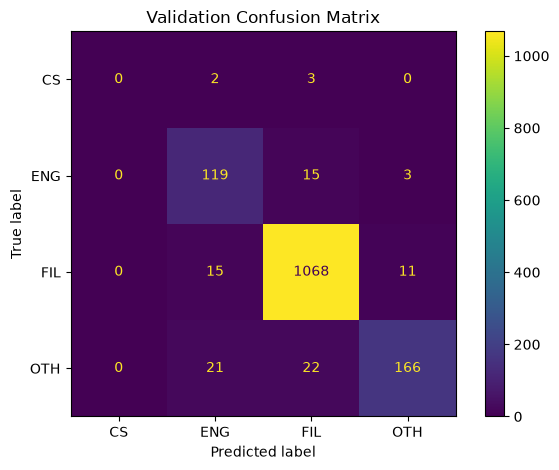

In [7]:
# 7. VALIDATION EVALUATION

print('VALIDATION CLASSIFICATION REPORT')
print('=' * 60)

print(classification_report(
    y_validation,
    validation_predictions,
    labels=['CS', 'ENG', 'FIL', 'OTH'],
    digits=4,
    zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    y_validation,
    validation_predictions,
    labels=['CS', 'ENG', 'FIL', 'OTH']
)

plt.title('Validation Confusion Matrix')
plt.tight_layout()
plt.show()


In [8]:
# 8. RETRAIN USING TRAIN + VALIDATION

# Validation is done, so combine both before the final internal test

train_validation_df = pd.concat([train_df, validation_df]).sort_index()

train_validation_features = (
    train_validation_df['word']
    .apply(extract_features)
    .tolist()
)

test_features = test_df['word'].apply(extract_features).tolist()

test_vectorizer = DictVectorizer(sparse=True)

X_train_validation = test_vectorizer.fit_transform(train_validation_features)
X_test_final = test_vectorizer.transform(test_features)

y_train_validation = train_validation_df['FINAL_ANNOTATION'].to_numpy()

test_model = RandomForestClassifier(
    n_estimators=300,
    max_depth=40,
    max_features='sqrt',
    class_weight='balanced_subsample',
    random_state=RANDOM_STATE,
    n_jobs=-1
)

test_model.fit(X_train_validation, y_train_validation)
test_predictions = test_model.predict(X_test_final)


FINAL TEST CLASSIFICATION REPORT
              precision    recall  f1-score   support

          CS     1.0000    0.6000    0.7500         5
         ENG     0.7895    0.8759    0.8304       137
         FIL     0.9704    0.9881    0.9792      1094
         OTH     0.9774    0.8238    0.8941       210

    accuracy                         0.9523      1446
   macro avg     0.9343    0.8220    0.8634      1446
weighted avg     0.9544    0.9523    0.9519      1446

Test accuracy: 0.9523


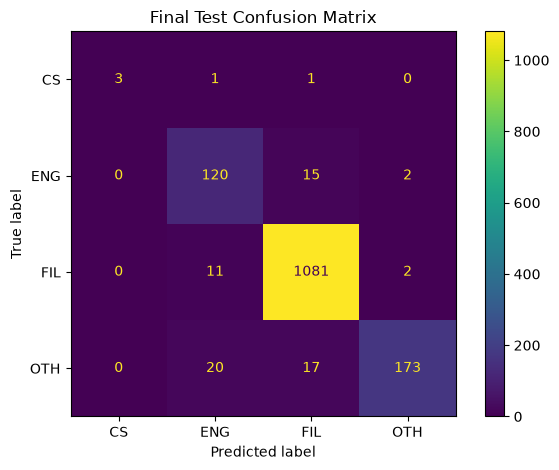

In [9]:
# 9. FINAL TEST EVALUATION

print('FINAL TEST CLASSIFICATION REPORT')
print('=' * 60)

print(classification_report(
    y_test,
    test_predictions,
    labels=['CS', 'ENG', 'FIL', 'OTH'],
    digits=4,
    zero_division=0
))

print('Test accuracy:', round(accuracy_score(y_test, test_predictions), 4))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    test_predictions,
    labels=['CS', 'ENG', 'FIL', 'OTH']
)

plt.title('Final Test Confusion Matrix')
plt.tight_layout()
plt.show()


In [10]:
# 10. Quick CHECK CS TEST RESULTS

results = test_df[
    ['sentence_id', 'word_id', 'word', 'FINAL_ANNOTATION']
].copy()

results['PREDICTION'] = test_predictions
results['CORRECT'] = results['FINAL_ANNOTATION'] == results['PREDICTION']

cs_results = results[
    (results['FINAL_ANNOTATION'] == 'CS')
    | (results['PREDICTION'] == 'CS')
]

display(cs_results)


,sentence_id,word_id,word,FINAL_ANNOTATION,PREDICTION,CORRECT
4242,218,4242,nagpa-relax-relax,CS,CS,True
4908,257,4908,nag-crash,CS,CS,True
5578,291,5578,nagpapa-test,CS,CS,True
8470,439,8470,nakakapagdecide,CS,FIL,False
9557,495,9557,marerealize,CS,ENG,False


In [11]:
# 11. RETRAIN ALL DATA AND SAVE WITH CLOUDPICKLE

# Cloudpickle saves the trained model, vectorizer, and feature function
# Para magamit ulit sa pinoybot.py without retraining


all_features = df['word'].apply(extract_features).tolist()
all_labels = df['FINAL_ANNOTATION'].to_numpy()

final_vectorizer = DictVectorizer(sparse=True)
X_all = final_vectorizer.fit_transform(all_features)

final_model = RandomForestClassifier(
    n_estimators=300,
    max_depth=40,
    max_features='sqrt',
    class_weight='balanced_subsample',
    random_state=RANDOM_STATE,
    n_jobs=-1
)

final_model.fit(X_all, all_labels)

artifact = {
    'vectorizer': final_vectorizer,
    'model': final_model,
    'extract_features': extract_features,
    'labels': LABELS,
    'random_state': RANDOM_STATE,
    'model_type': 'RandomForestClassifier',
    'feature_version': 'final_original_features_fixed_v1'
}

with open('model.pkl', 'wb') as file:
    cloudpickle.dump(artifact, file)

print('Saved model.pkl using cloudpickle')


Saved model.pkl using cloudpickle


In [12]:
# 12. QUICK SAVED MODEL CHECK lang

with open('model.pkl', 'rb') as file:
    saved = cloudpickle.load(file)

sample_words = ['Love', 'kita', 'nag-crash', 'DLSU', '.']
sample_features = [saved['extract_features'](word) for word in sample_words]
sample_matrix = saved['vectorizer'].transform(sample_features)
sample_predictions = saved['model'].predict(sample_matrix)

for word, prediction in zip(sample_words, sample_predictions):
    print(f'{word:12} -> {prediction}')


Love         -> ENG
kita         -> FIL
nag-crash    -> CS
DLSU         -> OTH
.            -> OTH
